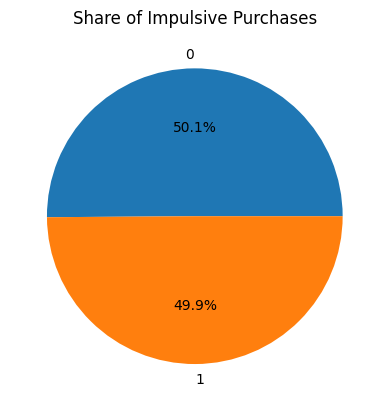

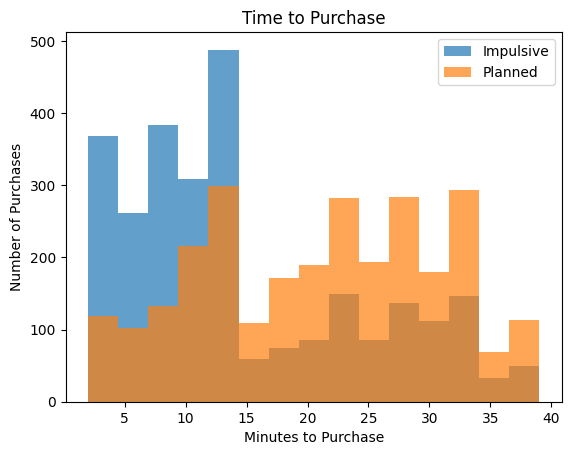

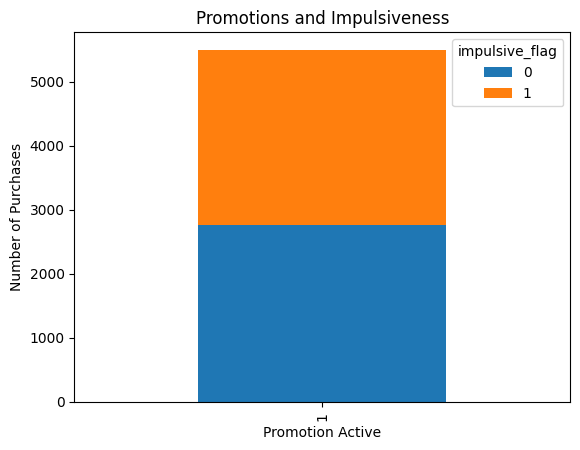

C:\Users\UserS2025\AppData\Local\Temp\ipykernel_18720\2644100010.py:106: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


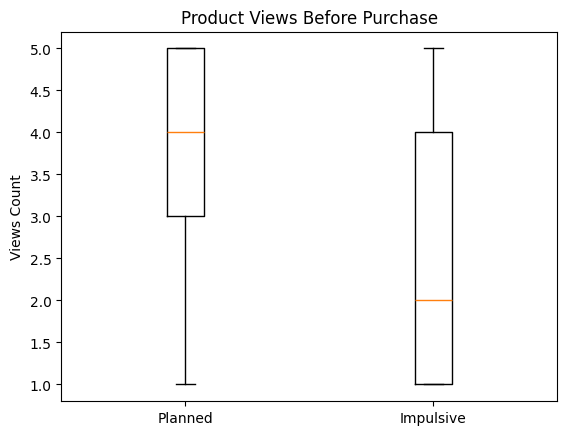

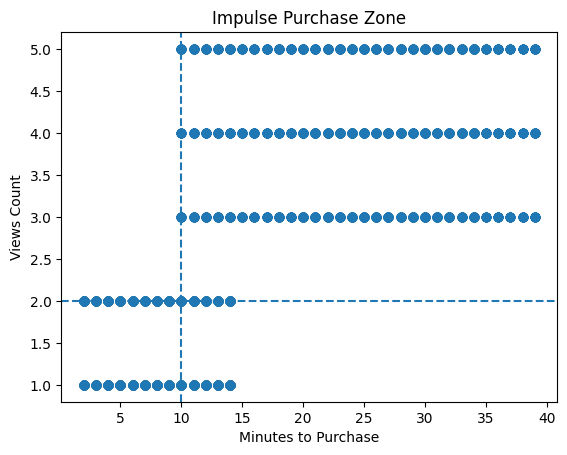

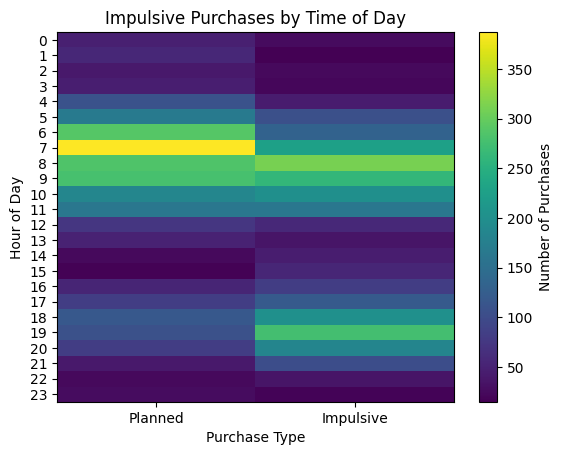

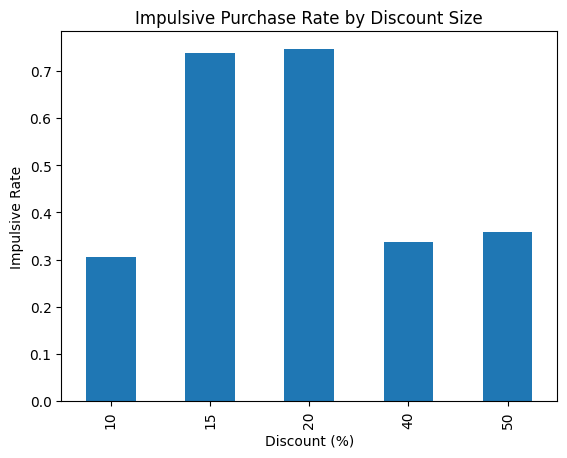

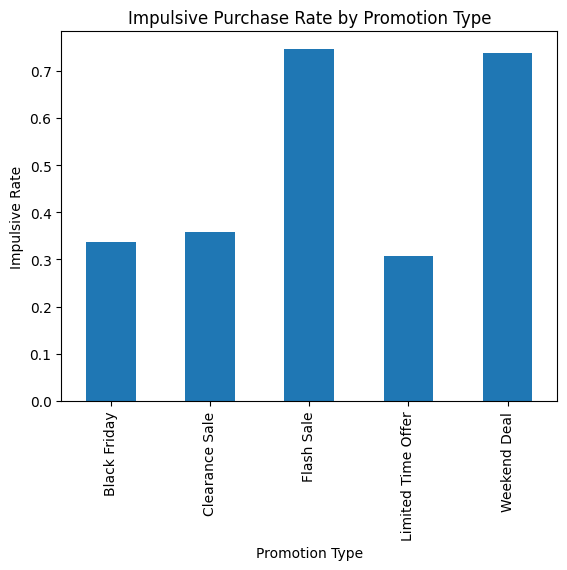

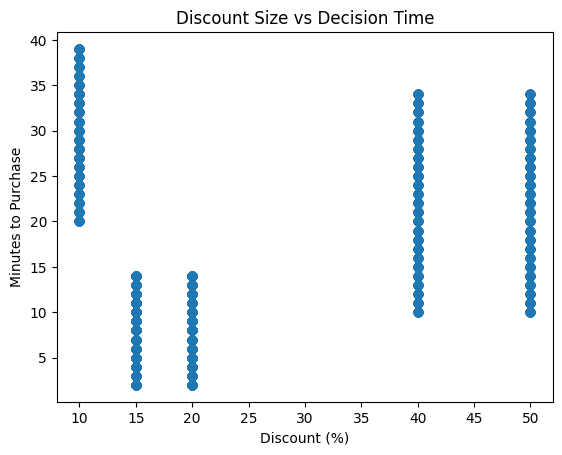

C:\Users\UserS2025\AppData\Local\Temp\ipykernel_18720\2644100010.py:163: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


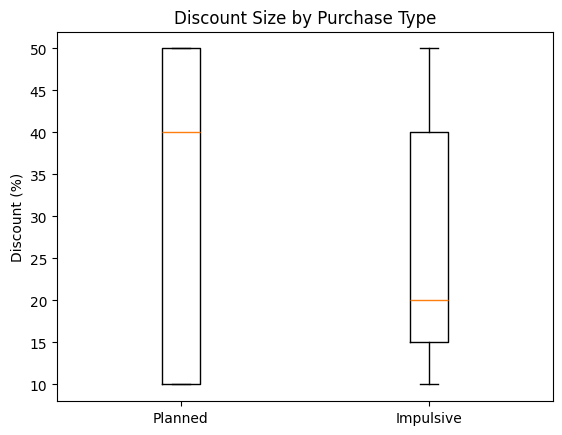

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# 1️⃣ DATA GENERATION (Synthetic but realistic dataset)
# =====================================================
np.random.seed(42)

promotions = [
    ("Limited Time Offer", 10),
    ("Weekend Deal", 15),
    ("Flash Sale", 20),
    ("Black Friday", 40),
    ("Clearance Sale", 50)
]

rows = []

# Часы и веса для спонтанных и плановых покупок
hours = np.arange(0, 24)

# Импульсивные — чаще в обед и вечер
impulse_weights = np.array([0.01,0.01,0.01,0.01,0.02,0.05,0.08,0.12,0.15,0.12,0.10,0.08,
                            0.03,0.02,0.02,0.03,0.04,0.06,0.10,0.15,0.10,0.05,0.02,0.01])
impulse_weights /= impulse_weights.sum()

# Плановые — чаще утром и днём
planned_weights = np.array([0.02,0.02,0.02,0.02,0.05,0.08,0.12,0.15,0.12,0.10,0.08,0.06,
                            0.03,0.02,0.01,0.01,0.02,0.03,0.05,0.05,0.03,0.02,0.01,0.01])
planned_weights /= planned_weights.sum()

for i in range(5500):
    promo_name, discount = promotions[np.random.randint(0, len(promotions))]

    # Логика импульсивности по размеру скидки
    if discount <= 10:
        impulsive_flag = np.random.choice([1, 0], p=[0.30, 0.70])
        views = np.random.randint(3, 6)
        minutes = np.random.randint(20, 40)
    elif discount <= 20:
        impulsive_flag = np.random.choice([1, 0], p=[0.75, 0.25])
        views = np.random.randint(1, 3)
        minutes = np.random.randint(2, 15)
    else:
        impulsive_flag = np.random.choice([1, 0], p=[0.35, 0.65])
        views = np.random.randint(3, 6)
        minutes = np.random.randint(10, 35)

    # Реалистичный час покупки
    hour = np.random.choice(
        hours, 
        p=impulsive_flag * impulse_weights + (1 - impulsive_flag) * planned_weights
    )

    rows.append({
        "user_id": f"U{i+1:03d}",
        "product_id": f"P{np.random.randint(100,999)}",
        "views_count": views,
        "minutes_to_purchase": minutes,
        "hour": hour,
        "promotion_name": promo_name,
        "discount_percent": discount,
        "impulsive_flag": impulsive_flag,
        "promotion_flag": 1
    })

df = pd.DataFrame(rows)

# =====================================================
# 2️⃣ Preview
# =====================================================
# print(df.head(12))

# =====================================================
# 3️⃣ VISUAL ANALYSIS
# =====================================================

# 1️⃣ Share of impulsive purchases
plt.figure()
df["impulsive_flag"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Share of Impulsive Purchases")
plt.ylabel("")
plt.show()

# 2️⃣ Time to purchase (Impulsive vs Planned)
plt.figure()
plt.hist(df[df["impulsive_flag"] == 1]["minutes_to_purchase"], bins=15, alpha=0.7, label="Impulsive")
plt.hist(df[df["impulsive_flag"] == 0]["minutes_to_purchase"], bins=15, alpha=0.7, label="Planned")
plt.xlabel("Minutes to Purchase")
plt.ylabel("Number of Purchases")
plt.legend()
plt.title("Time to Purchase")
plt.show()

# 3️⃣ Promotions and impulsive behavior
promo_table = pd.crosstab(df["promotion_flag"], df["impulsive_flag"])
promo_table.plot(kind="bar", stacked=True)
plt.xlabel("Promotion Active")
plt.ylabel("Number of Purchases")
plt.title("Promotions and Impulsiveness")
plt.show()

# 4️⃣ Product views before purchase
plt.figure()
plt.boxplot(
    [
        df[df["impulsive_flag"] == 0]["views_count"],
        df[df["impulsive_flag"] == 1]["views_count"]
    ],
    labels=["Planned", "Impulsive"]
)
plt.ylabel("Views Count")
plt.title("Product Views Before Purchase")
plt.show()

# 5️⃣ Time vs Views (Impulse zone)
plt.figure()
plt.scatter(df["minutes_to_purchase"], df["views_count"])
plt.axvline(10, linestyle="--")
plt.axhline(2, linestyle="--")
plt.xlabel("Minutes to Purchase")
plt.ylabel("Views Count")
plt.title("Impulse Purchase Zone")
plt.show()

# 6️⃣ Heatmap: Hour of day × Purchase type
heat = pd.crosstab(df["hour"], df["impulsive_flag"])
plt.figure()
plt.imshow(heat, aspect="auto")
plt.xticks([0, 1], ["Planned", "Impulsive"])
plt.yticks(range(len(heat.index)), heat.index)
plt.colorbar(label="Number of Purchases")
plt.xlabel("Purchase Type")
plt.ylabel("Hour of Day")
plt.title("Impulsive Purchases by Time of Day")
plt.show()

# 7️⃣ Discount → Impulsive rate
df.groupby("discount_percent")["impulsive_flag"].mean().plot(kind="bar")
plt.xlabel("Discount (%)")
plt.ylabel("Impulsive Rate")
plt.title("Impulsive Purchase Rate by Discount Size")
plt.show()

# 8️⃣ Promotion type → Impulsive rate
df.groupby("promotion_name")["impulsive_flag"].mean().plot(kind="bar")
plt.xlabel("Promotion Type")
plt.ylabel("Impulsive Rate")
plt.title("Impulsive Purchase Rate by Promotion Type")
plt.show()

# 9️⃣ Discount vs decision time
plt.figure()
plt.scatter(df["discount_percent"], df["minutes_to_purchase"])
plt.xlabel("Discount (%)")
plt.ylabel("Minutes to Purchase")
plt.title("Discount Size vs Decision Time")
plt.show()

# 🔟 Discount by purchase type
plt.figure()
plt.boxplot(
    [
        df[df["impulsive_flag"] == 0]["discount_percent"],
        df[df["impulsive_flag"] == 1]["discount_percent"]
    ],
    labels=["Planned", "Impulsive"]
)
plt.ylabel("Discount (%)")
plt.title("Discount Size by Purchase Type")
plt.show()


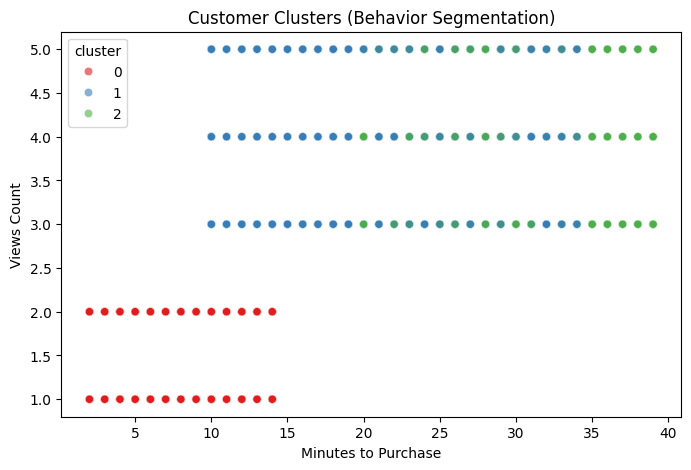

No 'day_of_week' column found. Skipping time series by day of week.


C:\Users\UserS2025\AppData\Local\Temp\ipykernel_18720\3097404250.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Users', y='Stage', data=funnel_df, palette='Blues_r')


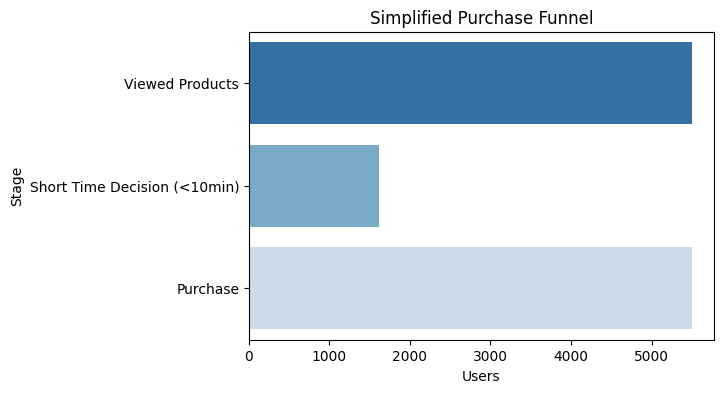

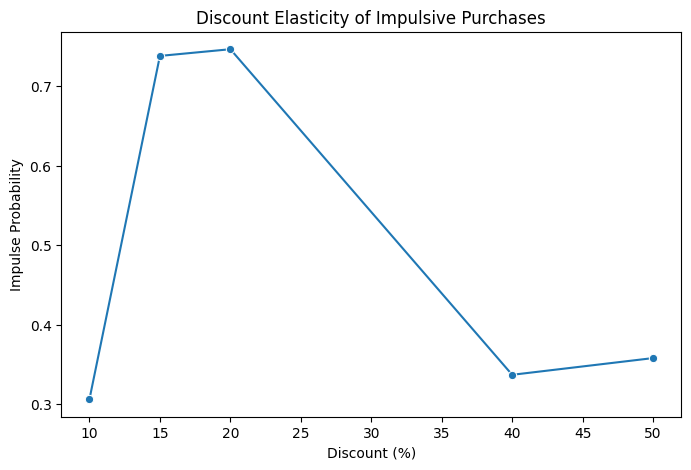

TypeError: DataFrame.pivot() takes 1 positional argument but 4 were given

<Figure size 800x500 with 0 Axes>

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from mlxtend.frequent_patterns import apriori, association_rules

# =====================================================
# Скрипт для продвинутой визуализации и анализа
# =====================================================

# ----------------------------
# 1️⃣ Clustering покупателей
# ----------------------------
# Цель: разделить покупателей на группы по поведению
# Используем признаки: minutes_to_purchase, views_count, discount_percent
features = df[['minutes_to_purchase','views_count','discount_percent']]
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(features)

plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='minutes_to_purchase', 
    y='views_count', 
    hue='cluster', 
    palette='Set1', 
    alpha=0.6
)
plt.xlabel("Minutes to Purchase")
plt.ylabel("Views Count")
plt.title("Customer Clusters (Behavior Segmentation)")
plt.show()

# ----------------------------
# 2️⃣ Basket Analysis / Association Rules
# ----------------------------
# Цель: выявить комбинации товаров, которые часто покупают импульсивно
# Для простоты делаем бинарную матрицу: product_id x purchase occurrence
#basket = pd.crosstab(df['user_id'], df['product_id'])
#basket = basket.applymap(lambda x: 1 if x>0 else 0)
## Частые комбинации
#frequent_itemsets = apriori(basket, min_support=0.1, use_colnames=True)
#rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
#rules_impulsive = rules[rules['antecedents'].apply(lambda x: any(prod in x for prod in df[df['impulsive_flag']==1]['product_id'].unique()))]

#print("Top 5 association rules involving impulsive purchases:")
#print(rules_impulsive.sort_values('lift', ascending=False).head(5))

# ----------------------------
# 3️⃣ Time Series: Hourly Activity by Day of Week
# ----------------------------
# Цель: показать пики активности импульсивных и плановых покупателей по часам
if 'day_of_week' in df.columns:
    plt.figure(figsize=(8,5))
    sns.lineplot(data=df[df['impulsive_flag']==1].groupby(['day_of_week','hour'])['user_id'].count().reset_index(),
                 x='hour', y='user_id', hue='day_of_week', marker='o')
    plt.title("Hourly Impulsive Purchase Activity by Day of Week")
    plt.xlabel("Hour")
    plt.ylabel("Number of Purchases")
    plt.show()
else:
    print("No 'day_of_week' column found. Skipping time series by day of week.")

# ----------------------------
# 4️⃣ Funnel Analysis
# ----------------------------
# Цель: показать воронку покупателей
# Здесь используем упрощенно: views_count → minutes_to_purchase → purchase
# Считаем, сколько пользователей дошли до каждой стадии
total_users = df['user_id'].nunique()
funnel_stages = [
    ('Viewed Products', df['views_count'].ge(1).sum()),
    ('Short Time Decision (<10min)', df['minutes_to_purchase'].le(10).sum()),
    ('Purchase', df.shape[0])
]
funnel_df = pd.DataFrame(funnel_stages, columns=['Stage','Users'])

plt.figure(figsize=(6,4))
sns.barplot(x='Users', y='Stage', data=funnel_df, palette='Blues_r')
plt.title("Simplified Purchase Funnel")
plt.show()

# ----------------------------
# 5️⃣ Discount Elasticity
# ----------------------------
# Цель: как вероятность импульсивной покупки зависит от скидки
# Рассчитываем среднюю долю импульсивных по дискаунту
discount_df = df.groupby('discount_percent')['impulsive_flag'].mean().reset_index()
plt.figure(figsize=(8,5))
sns.lineplot(data=discount_df, x='discount_percent', y='impulsive_flag', marker='o')
plt.xlabel("Discount (%)")
plt.ylabel("Impulse Probability")
plt.title("Discount Elasticity of Impulsive Purchases")
plt.show()

# ----------------------------
# 6️⃣ Cohort Analysis
# ----------------------------
# Цель: посмотреть повторные импульсивные покупки по когортам
# Для примера используем 'user_id' + 'impulsive_flag'
# Создаем когорту по первому импульсивному покупателю
first_purchase = df[df['impulsive_flag']==1].groupby('user_id')['hour'].min().reset_index()
first_purchase.rename(columns={'hour':'cohort_hour'}, inplace=True)
df_cohort = df.merge(first_purchase, on='user_id', how='left')
cohort_analysis = df_cohort.groupby(['cohort_hour','hour'])['user_id'].nunique().reset_index()
plt.figure(figsize=(8,5))
sns.heatmap(cohort_analysis.pivot('cohort_hour','hour','user_id'), annot=True, fmt='d', cmap='YlGnBu')
plt.title("Cohort Analysis of Impulsive Purchases")
plt.xlabel("Hour of Purchase")
plt.ylabel("Cohort Hour")
plt.show()

# ----------------------------
# 7️⃣ Conversion Probability Heatmap
# ----------------------------
# Цель: показать вероятность импульсивной покупки по minutes_to_purchase и views_count
heatmap_df = df.groupby(['minutes_to_purchase','views_count'])['impulsive_flag'].mean().reset_index()
heatmap_pivot = heatmap_df.pivot('views_count','minutes_to_purchase','impulsive_flag')
plt.figure(figsize=(10,6))
sns.heatmap(heatmap_pivot, cmap='Reds', annot=True, fmt=".2f")
plt.xlabel("Minutes to Purchase")
plt.ylabel("Views Count")
plt.title("Conversion Probability Heatmap (Impulse)")
plt.show()
